In [1]:
import warnings
from pathlib import Path
import os
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd
import seaborn as sns
# from matplotlib.lines import Line2D
# from matplotlib.patches import Patch
# from shapely.geometry import box
# from shapely.ops import linemerge, substring
import gis_functions as gis
from collections import Counter
import re

In [2]:
# load in geograpgy dataset
gpkg_dir = "output/greater_boston_subset.gpkg"
gpkg_layers = {name: gpd.read_file(gpkg_dir, layer=name) for name in gpd.list_layers(gpkg_dir)["name"]}

g_bike, g_lines, g_stations = gpkg_layers["bike_network"], gpkg_layers["mbta_lines"], gpkg_layers["mbta_stations"]
g_districts, g_towns = gpkg_layers["districts"], gpkg_layers["towns"]
g_bike2, g_trails = gpkg_layers["bike_recreation"], gpkg_layers["bike_trails"]
g_roads = gpkg_layers["roads"]

boston_town = g_towns[g_towns.TOWN.str.upper() == 'BOSTON']
# boston_roads = boston_roads.to_crs(boston_town.crs)
boston_roads = g_roads[g_roads.MGIS_TOWN.str.upper() == 'BOSTON']
# boston_bike = boston_bike.to_crs(boston_town.crs)
boston_bike = g_bike.clip(boston_town)
# boston_district = boston_district.to_crs(boston_town.crs)
boston_district = g_districts[g_districts.MUNI.str.upper() == 'BOSTON']
# boston_full = pd.concat([boston_town, boston_district, boston_roads, boston_bike])

<Axes: >

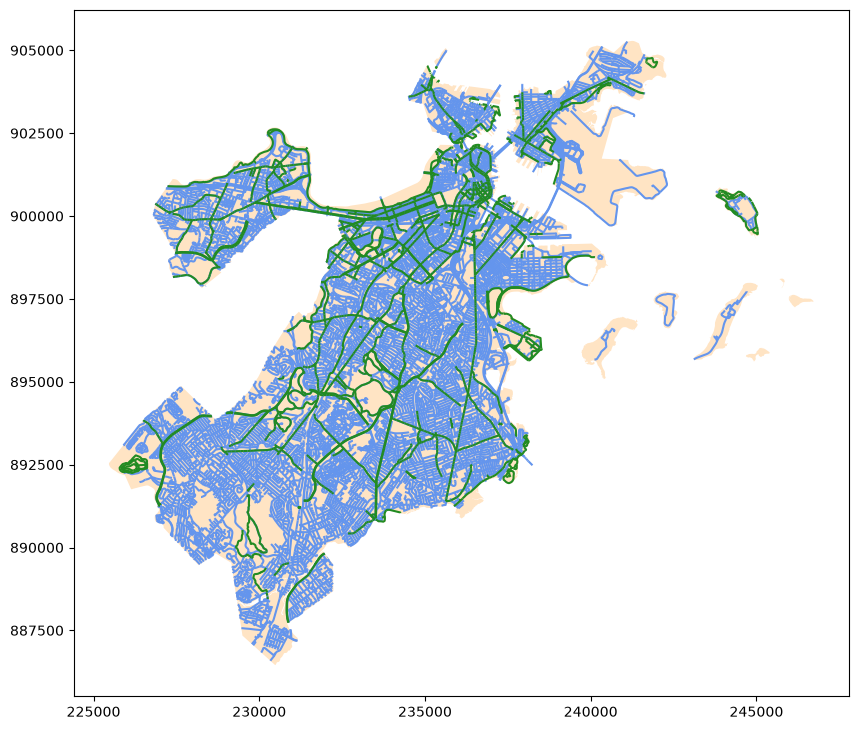

In [3]:
# plot boston
# boston_full.plot()
f, ax = plt.subplots(figsize=(10, 10))
boston_town.plot(ax=ax, color="bisque", zorder=1)
# boston_district.plot(ax=ax, color="skyblue", zorder=2)
boston_roads.plot(ax=ax, color="cornflowerblue", zorder=3)
boston_bike.plot(ax=ax, color="forestgreen", zorder=4)

In [4]:
## traffic data

# read in data
data_dir = "/Users/diksh/Documents/BCU/AnnualReport2026/data/traffic/"
data_files = os.listdir(data_dir)

frames = []
for f in data_files:
    print(f)
    new_pd = pd.read_csv(data_dir+f)
    frames.append(new_pd)
dat = pd.concat(frames)
dat_avg = dat.groupby('location_name', as_index=False)['day_bikes'].mean()

# normalize traffic by street length?
# which seasons to include?

Streets_Daily_Bike_Counts_Fall2026.csv
Streets_Daily_Bike_Counts_Spring2026.csv
Streets_Daily_Bike_Counts_Summer2026.csv
Streets_Daily_Bike_Counts_Winter2025.csv


Text(0.5, 1.0, 'Bike Traffic Across Season (Winter 2025 - Fall 2026)')

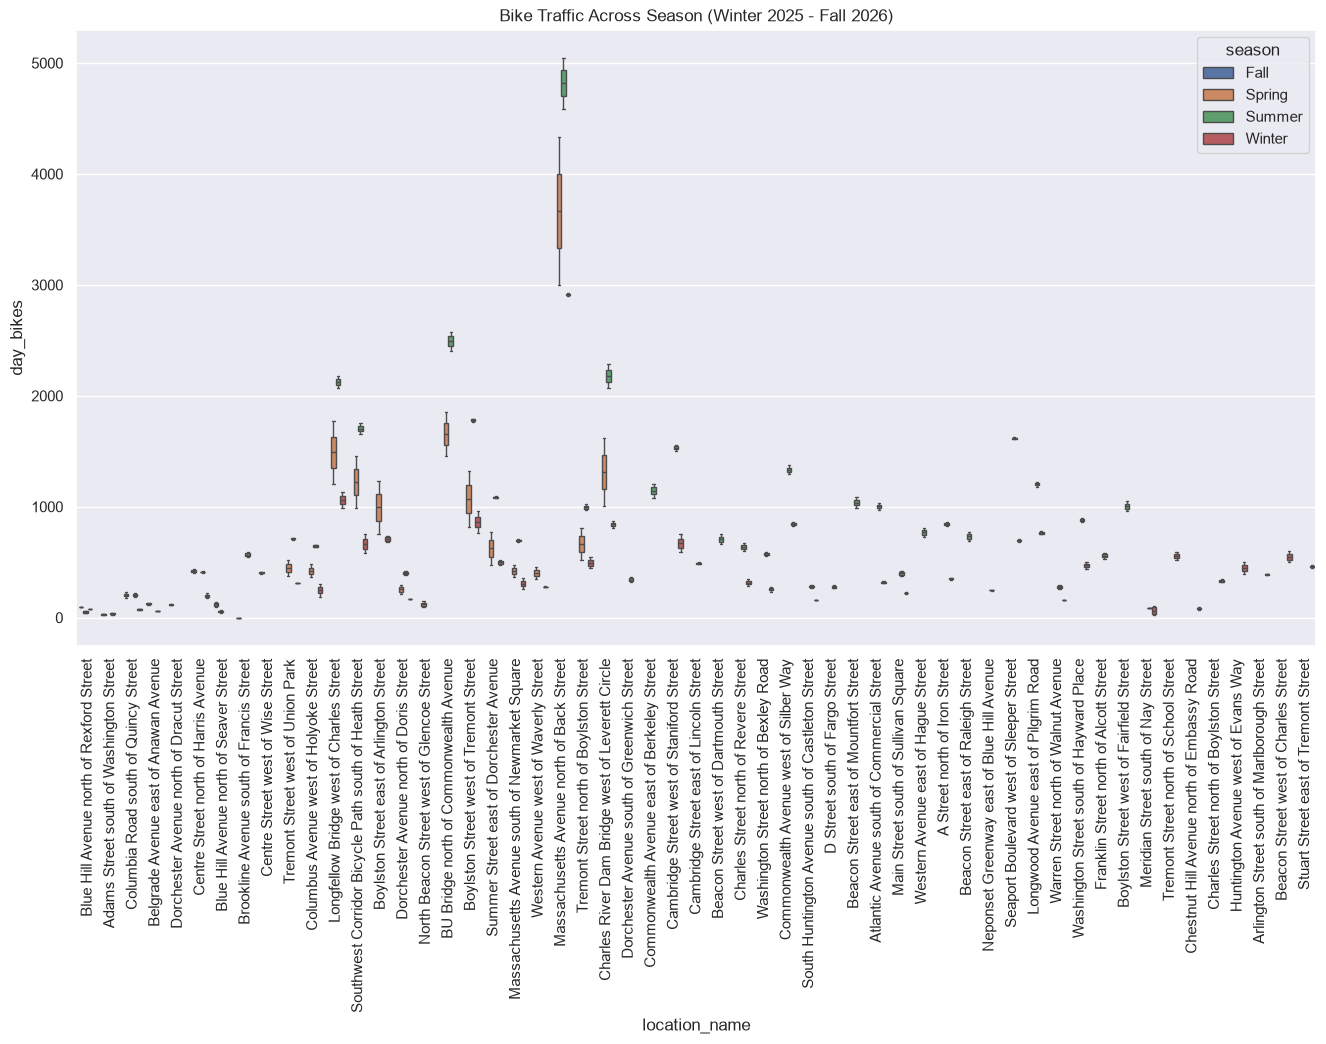

In [5]:
# histogram across seasons
sns.set(rc={"figure.figsize":(16, 8)})
plt.xticks(rotation=90)
p = sns.boxplot(data=dat, x = 'location_name', y = 'day_bikes', hue = 'season')
p.set_title("Bike Traffic Across Season (Winter 2025 - Fall 2026)")
# p.figure.savefig("/Users/diksh/Documents/BCU/AnnualReport2026/figs/traffic_seasons.png", dpi=300, bbox_inches="tight")
# plt.close(p.figure)

Text(0.5, 1.0, 'Averaged Bike Traffic (Winter 2025 - Fall 2026)')

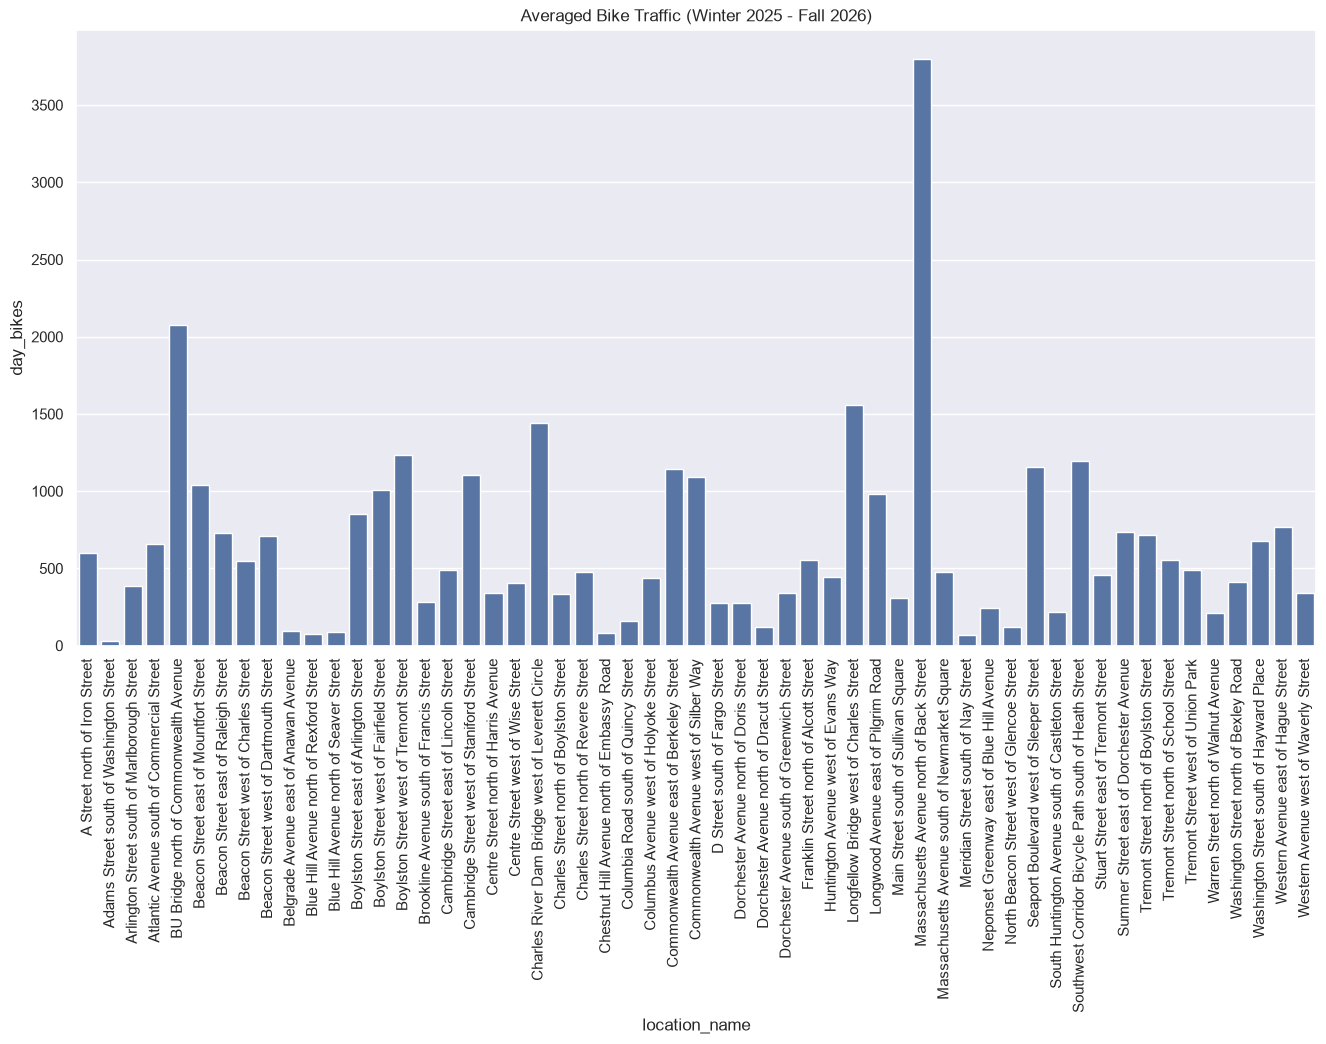

In [6]:
# average for each counting location
col = 'day_bikes'
dat_avg = dat.groupby('location_name', as_index=False)['day_bikes'].mean()
# order = dat_avg[col].value_counts().index
# plot_df = dat_avg.assign(**{col: pd.Categorical(dat_avg[col], categories=order, ordered=True)})

plt.xticks(rotation=90)
p = sns.barplot(data=dat_avg, x = 'location_name', y = 'day_bikes')
p.set_title("Averaged Bike Traffic (Winter 2025 - Fall 2026)")
# p.figure.savefig("/Users/diksh/Documents/BCU/AnnualReport2026/figs/traffic_avg.png", dpi=300, bbox_inches="tight")
# plt.close(p.figure)

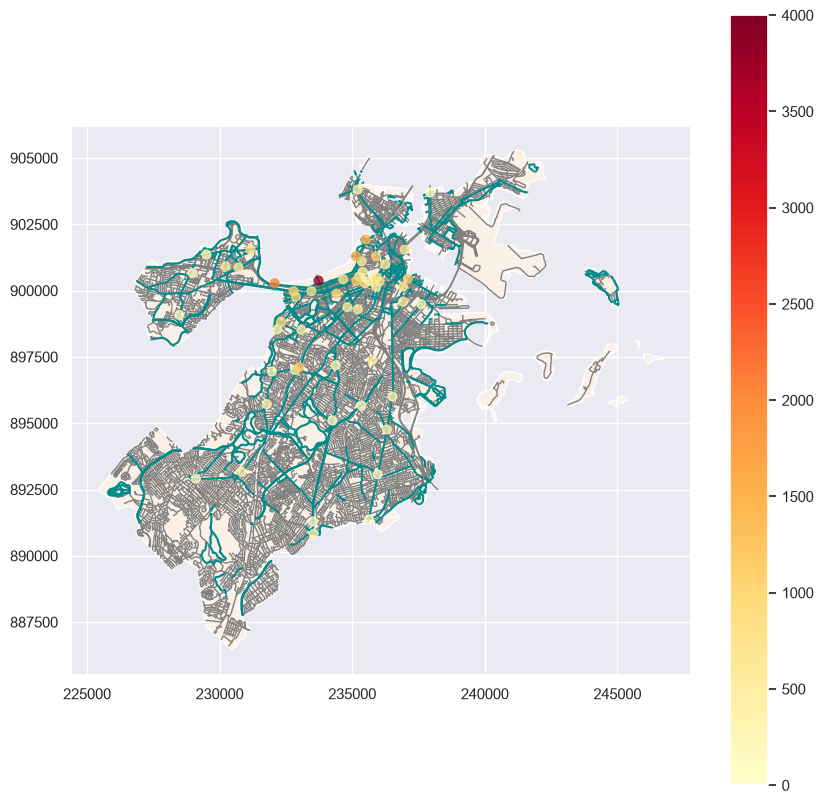

In [14]:
# make traffic map
# get positions
lat_list = []
lon_list = []
for i in dat_avg.index:
    idx = list(dat['location_name']).index(dat_avg['location_name'][i])
    lat_list.append(dat.iloc[idx, 7])
    lon_list.append(dat.iloc[idx, 8])

# construct dataframe
dat_avg['lat'] = lat_list
dat_avg['lon'] = lon_list

tf_df = gpd.GeoDataFrame(
    dat_avg, geometry=gpd.points_from_xy(dat_avg.lon, dat_avg.lat), crs="EPSG:4326"
).to_crs(boston_roads.crs)  

# plot
f, ax = plt.subplots(figsize=(10, 10))
boston_town.plot(ax=ax, color="linen", zorder=1)
boston_roads.plot(ax=ax,linewidth=1, color="gray", zorder=2)
boston_bike.plot(ax=ax, color="darkcyan", zorder=3)
tf_df.plot(ax=ax, markersize=40, column="day_bikes",               # the column that sets the color
    cmap="YlOrRd", zorder=4, alpha=0.75, legend=True, vmin=0, vmax=4000)
f.savefig("avg_traffic_counts_map.png", dpi=500, bbox_inches="tight")

In [15]:
# write to file
dat_avg.to_csv('C:/Users/diksh/Documents/BCU/AnnualReport2026/analysis/avg_bike_traffic.csv')

In [4]:
## crash data (streets)

# read in data
data_file = "/Users/diksh/Documents/BCU/AnnualReport2026/data/crash/crashdata.csv"
dat = pd.read_csv(data_file)
# dat["ts"] = pd.to_datetime(dat["dispatch_ts"], utc=True)
dat[dat["dispatch_ts"] >= "2026-01-01"]
dat = dat[(dat['location_type'] == 'Street') & (dat['mode_type'] == 'bike')]
# st_dat

# normalize frequency of crashes by length of street?
# include intersections? how to decide which street that counts under? both probably
# how do we know if crashes between bike + car is under bike or mv, or is it both?

cts = Counter(dat['street'])
# cts
ct_df = pd.DataFrame(cts.items(), columns=["street", "count"])

# fix street names
street_endings = [s.split()[-1] for s in dat['street']]
# dat['street'].split("_")
set(street_endings)
ct_df['Street'] = gis.fix_street_abbrevs(ct_df['street']) #fixed_streets

# get length of each street
ct_df['length'] = 0.0
for i in ct_df.index:
    st = ct_df.loc[i, 'Street']
    if st == 'coord error':
        continue
    else:
        # print(st)
        l = gis.street_length(city=boston_roads, target_street=st, units='miles')
        # print(l)
        ct_df.loc[i, 'length'] = l
ct_df['crashesPerMile'] = ct_df['count']/ct_df['length'] # normalize counts by length
ct_df=ct_df.sort_values("crashesPerMile", ascending=False)
ct_df.to_csv("C:/Users/diksh/Documents/BCU/AnnualReport2026/analysis/bike_crashes_street.csv")
ct_df

,street,count,Street,length,crashesPerMile
385,LEVERETT CIR,4,LEVERETT CIRCLE,0.006146,650.867807
277,BROADWAY,6,BROADWAY,0.046056,130.275431
412,JAMES ONEILL ST,2,JAMES ONEILL STREET,0.025157,79.499732
463,HAROLD PARK,1,HAROLD PARK,0.019404,51.536585
298,KENSINGTON ST,2,KENSINGTON STREET,0.040779,49.045059
...,...,...,...,...,...
240,FIRST ST,2,FIRST STREET,-1.000000,-2.000000
57,TERMINAL RD,2,TERMINAL ROAD,-1.000000,-2.000000
144,FOURTH ST,2,FOURTH STREET,-1.000000,-2.000000
203,POST OFFICE SQ,3,POST OFFICE SQUARE,-1.000000,-3.000000


In [7]:
# checking to make sure specific streets exist in the geography dataset
boston_roads
sub = 'BOUNDARY'
# match = []
for s in list(boston_roads['STREETNAME']):
    if pd.isnull(s):
        continue
    if sub in s.upper():
        print(s)


WEST BOUNDARY ROAD
EAST BOUNDARY ROAD


Text(0.5, 1.0, 'Bike Crashes per Mile in 2026')

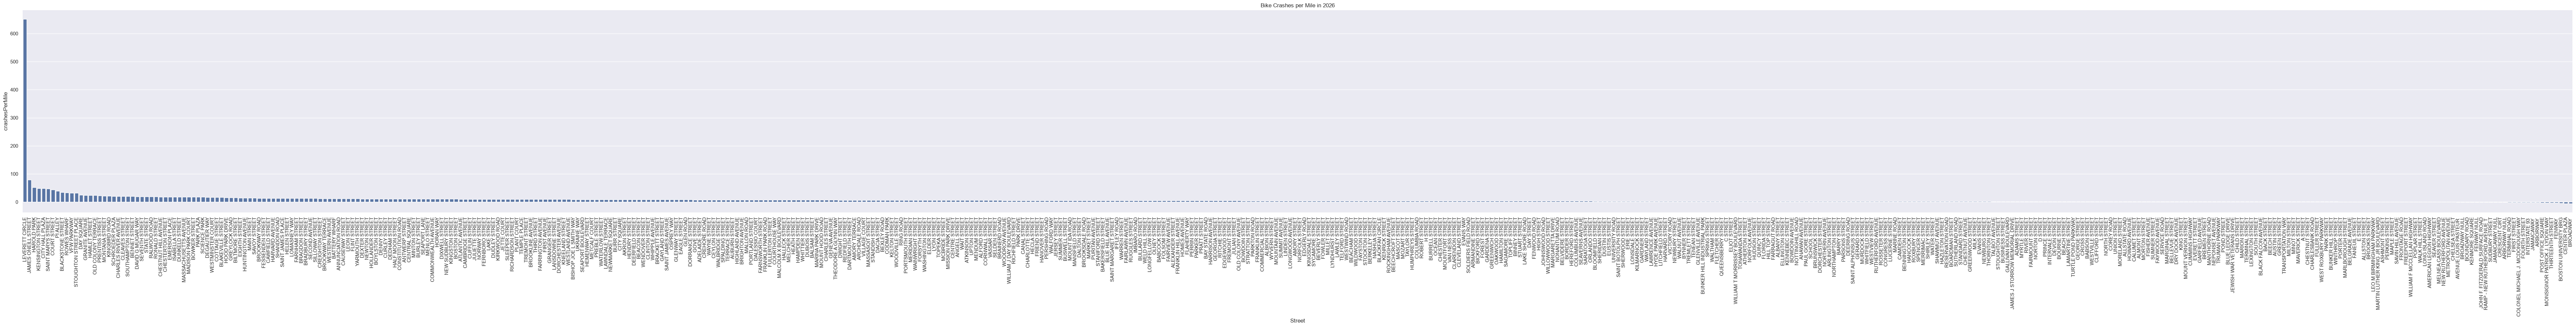

In [5]:
# plot barplot of bike crashes per mile
st_dat = ct_df
col = 'street'
order = st_dat[col].value_counts().index
plot_df = st_dat.assign(**{col: pd.Categorical(st_dat[col], categories=order, ordered=True)})

sns.set(rc={"figure.figsize":(100, 8)})
plt.xticks(rotation=90)
p = sns.barplot(data=plot_df, x = 'Street', y = 'crashesPerMile')
p.set_title("Bike Crashes per Mile in 2026")
# p.figure.savefig("/Users/diksh/Documents/BCU/AnnualReport2026/figs/crashes_total_ordered.png", dpi=600, bbox_inches="tight")
# plt.close(p.figure)

In [8]:
# plot_df.to_csv("C:/Users/diksh/Documents/BCU/AnnualReport2026/analysis/bike_crashes_street.csv")
# filter down to streets that have at least 3 counts and minimum length of 0.01 miles
ct_df = ct_df[(ct_df['count'] >= 3) & ct_df['length'] >= 0.01]
all_tgt_streets = list(set(ct_df['Street']))

# split streets into 0.5 mile segments (shifting the start point every 0.1 miles)
segment_length_miles = 0.5
frame_length_miles = 0.1 

segs = gis.split_streets(boston_roads, all_tgt_streets, 
                         seg_length=segment_length_miles*1609.344, frame_length=frame_length_miles*1609.344)
segs = gis.count_points_along_segments(segs, dat, lat_col='lat', long_col='long')
segs = segs[segs['count'] > 10]
segs = segs.sort_values('count', ascending=False)
# segs
segs_df = segs.drop(labels='geometry',axis=1)
segs_df.to_csv('C:/Users/diksh/Documents/BCU/AnnualReport2026/analysis/bike_crash_street_segmentsFrameShift.csv')

Text(0.5, 1.0, 'Bike Crashes Across Street Segments in 2026')

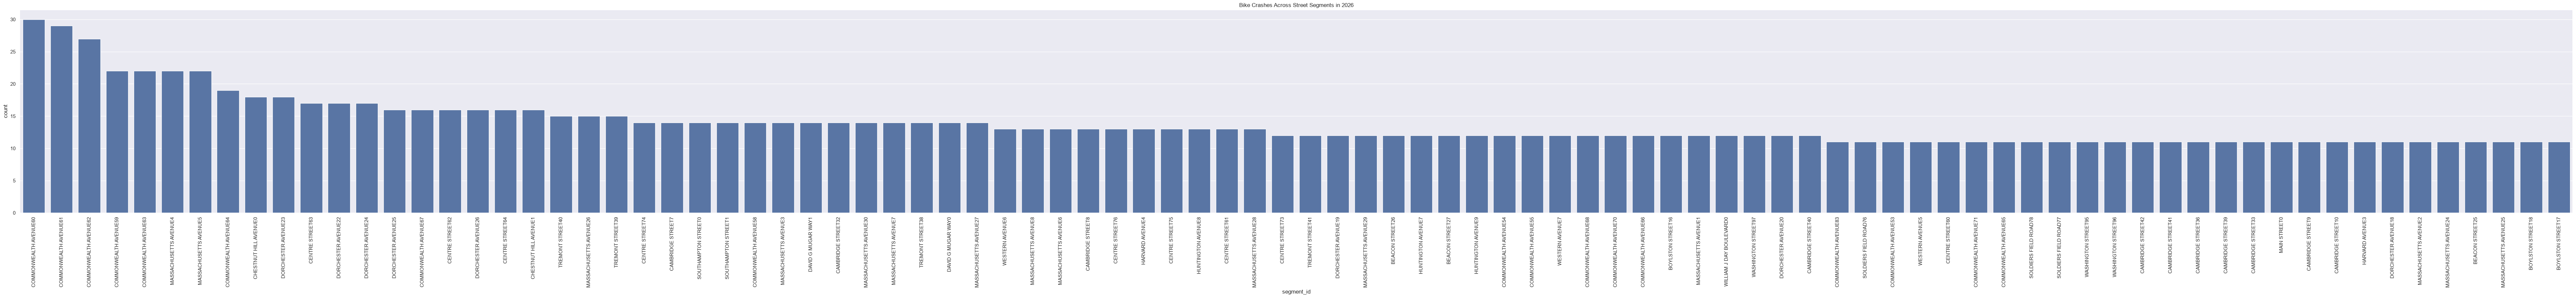

In [9]:
# plot coutns across segments
sns.set(rc={"figure.figsize":(100, 8)})
plt.xticks(rotation=90)
p = sns.barplot(data=segs, x = 'segment_id', y = 'count')
p.set_title("Bike Crashes Across Street Segments in 2026")


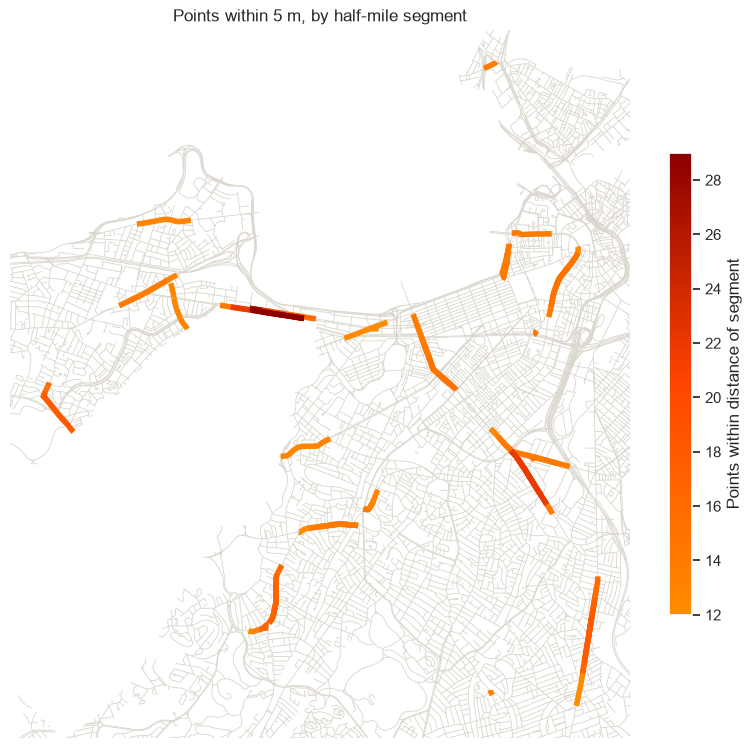

In [10]:
# plot top x segments on the map
plot_segs = segs[1:50]
plot_segs = plot_segs.sort_values('count', ascending=True)
gis.plot_segment_counts(plot_segs, background=boston_roads, 
                        title="Points within 5 m, by half-mile segment", 
                        cmap=LinearSegmentedColormap.from_list("col", ["darkorange", "orangered", "darkred"]),
                       linewidth=4)
plt.show()

In [11]:
## crash data (intersections)

# read in data, filter to 2026
data_file = "/Users/diksh/Documents/BCU/AnnualReport2026/data/crash/crashdata.csv"
dat = pd.read_csv(data_file)
# dat["ts"] = pd.to_datetime(dat["dispatch_ts"], utc=True)
dat[dat["dispatch_ts"] >= "2026-01-01"]
dat = dat[(dat['location_type'] == 'Intersection') & (dat['mode_type'] == 'bike')]
dat['XStreet1'] = gis.fix_street_abbrevs(dat['xstreet1'])
dat['XStreet2'] = gis.fix_street_abbrevs(dat['xstreet2'])

# make a unique id for each interasection
iid_list = []
for i in dat.index:
    sts = [dat.loc[i, 'XStreet1'], dat.loc[i, 'XStreet2']]
    sts.sort()
    iid = re.sub(' ', "_", sts[0] + "-x-" + sts[1])
    iid_list.append(iid)
dat['IntersectionID'] = iid_list
dat
# st_dat

,dispatch_ts,mode_type,location_type,street,xstreet1,xstreet2,x_cord,y_cord,lat,long,XStreet1,XStreet2,IntersectionID
21,2015-09-09 12:39:19+00,bike,Intersection,NaN,BEACON ST,MASSACHUSETTS AVE,767133.97,2953148.66,42.350858,-71.089484,BEACON STREET,MASSACHUSETTS AVENUE,BEACON_STREET-x-MASSACHUSETTS_AVENUE
34,2017-07-07 00:46:46+00,bike,Intersection,NaN,PARK DR,BOYLSTON ST,765823.66,2951207.40,42.345548,-71.094365,PARK DRIVE,BOYLSTON STREET,BOYLSTON_STREET-x-PARK_DRIVE
52,2019-10-11 15:25:29+00,bike,Intersection,NaN,MASSACHUSETTS AVE,COMMONWEALTH AVE,767364.62,2952528.83,42.349154,-71.088641,MASSACHUSETTS AVENUE,COMMONWEALTH AVENUE,COMMONWEALTH_AVENUE-x-MASSACHUSETTS_AVENUE
96,2015-08-16 02:55:20+00,bike,Intersection,NaN,ALBANY ST,TRAVELER ST,774560.11,2950701.90,42.344043,-71.062058,ALBANY STREET,TRAVELER STREET,ALBANY_STREET-x-TRAVELER_STREET
129,2018-06-01 04:45:47+00,bike,Intersection,NaN,WASHINGTON ST,KNEELAND ST,774300.14,2953232.83,42.350991,-71.062972,WASHINGTON STREET,KNEELAND STREET,KNEELAND_STREET-x-WASHINGTON_STREET
...,...,...,...,...,...,...,...,...,...,...,...,...,...
44906,2017-01-25 14:39:51+00,bike,Intersection,NaN,WESTERN AVE,SOLDIERS FIELD RD,752044.78,2956989.14,42.361582,-71.145245,WESTERN AVENUE,SOLDIERS FIELD ROAD,SOLDIERS_FIELD_ROAD-x-WESTERN_AVENUE
44946,2024-08-07 20:01:31+00,bike,Intersection,NaN,GENEVA AVE,WALDECK ST,773907.80,2934462.87,42.299491,-71.064777,GENEVA AVENUE,WALDECK STREET,GENEVA_AVENUE-x-WALDECK_STREET
44953,2018-03-11 03:20:32+00,bike,Intersection,NaN,MASSACHUSETTS AVE,ALBANY ST,771507.33,2946877.51,42.333591,-71.073421,MASSACHUSETTS AVENUE,ALBANY STREET,ALBANY_STREET-x-MASSACHUSETTS_AVENUE
44959,2016-10-09 13:26:56+00,bike,Intersection,NaN,GORDON ST,AMORY ST,762378.07,2938245.81,42.310025,-71.107331,GORDON STREET,AMORY STREET,AMORY_STREET-x-GORDON_STREET


In [12]:
# coutn crahes in each intersection and make a data frame
cts = Counter(dat['IntersectionID'])
# cts
ct_df = pd.DataFrame(cts.items(), columns=["Intersection", "count"])
ct_df = ct_df.sort_values('count', ascending=False)
ct_df

,Intersection,count
0,BEACON_STREET-x-MASSACHUSETTS_AVENUE,28
2,COMMONWEALTH_AVENUE-x-MASSACHUSETTS_AVENUE,27
33,ALBANY_STREET-x-MASSACHUSETTS_AVENUE,17
84,PRENTISS_STREET-x-TREMONT_STREET,15
210,N_HARVARD_STREET-x-SOLDIERS_FIELD_ROAD,14
...,...,...
1128,WAVERLY_STREET-x-WESTERN_AVENUE,1
1127,EVANS_WAY-x-LOUIS_PRANG_STREET,1
1126,KENBERMA_ROAD-x-WASHINGTON_STREET,1
1125,EUSTON_ROAD-x-WASHINGTON_STREET,1


Text(0.5, 1.0, 'Intersection Bike Crashes 2026')

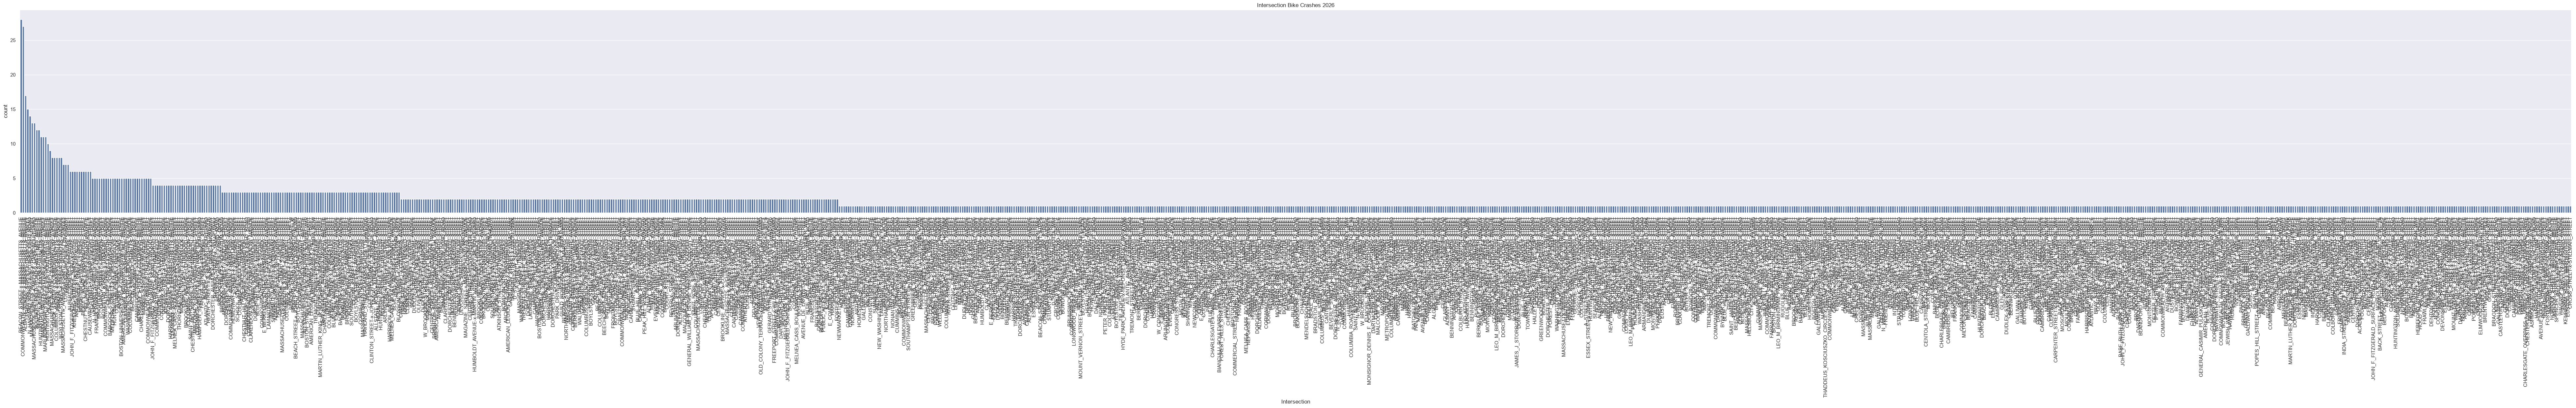

In [31]:
# plot counts for each intersection
sns.set(rc={"figure.figsize":(100, 8)})
plt.xticks(rotation=90)
p = sns.barplot(data=ct_df, x = 'Intersection', y = 'count')
p.set_title("Intersection Bike Crashes 2026")


In [13]:
# write to file
ct_df.to_csv('C:/Users/diksh/Documents/BCU/AnnualReport2026/analysis/bike_crash_intersections.csv')

In [14]:
# get top intersections
top_itcns = list(ct_df.loc[ct_df.index[range(10)],'Intersection'])
print(top_itcns)

# iterate over each intersection and get the actual locations from the geography dataset
intersect_pts = []
it_name = []
for i in top_itcns:
    streets = i.split("-x-")
    streets = [re.sub("_", " ", s) for s in streets]
    # print(streets)
    # correct for the points formatting
    itcn_pts = gis.street_intersection(boston_roads, streets[1], streets[0])
    itcn_pts = gpd.GeoSeries(itcn_pts)
    itcn_pts = itcn_pts.explode(ignore_index=True)
    if itcn_pts.shape[0] == 0:
        print("error in " + i)
        continue
    it_pt = itcn_pts[0]
    if it_pt.is_empty:
        print("error in " + i)
        continue
    
    intersect_pts.append(it_pt)
    it_name.append(i)

# get the points and geo data in the same formatting
intersections = gpd.GeoDataFrame(data=list(range(len(intersect_pts))), columns = ["idx"], geometry=intersect_pts)
intersections.crs = boston_roads.crs
intersections['name'] = it_name
intersections['value'] = 0
for i in intersections.index:
    tgt_it = intersections.loc[i, 'name']
    df_idx = ct_df.index[ct_df['Intersection'] == tgt_it].tolist()[0]
    # print(df_idx)
    # print(ct_df.loc[df_idx, 'count'])
    intersections.loc[i, 'value'] = ct_df.loc[df_idx, 'count']
intersections

['BEACON_STREET-x-MASSACHUSETTS_AVENUE', 'COMMONWEALTH_AVENUE-x-MASSACHUSETTS_AVENUE', 'ALBANY_STREET-x-MASSACHUSETTS_AVENUE', 'PRENTISS_STREET-x-TREMONT_STREET', 'N_HARVARD_STREET-x-SOLDIERS_FIELD_ROAD', 'MASSACHUSETTS_AVENUE-x-TREMONT_STREET', 'MASSACHUSETTS_AVENUE-x-MELNEA_CASS_BOULEVARD', 'SOLDIERS_FIELD_ROAD-x-WESTERN_AVENUE', 'BEACON_STREET-x-CHESTNUT_HILL_AVENUE', 'HUNTINGTON_AVENUE-x-MASSACHUSETTS_AVENUE']
error in N_HARVARD_STREET-x-SOLDIERS_FIELD_ROAD
error in MASSACHUSETTS_AVENUE-x-MELNEA_CASS_BOULEVARD


,idx,geometry,name,value
0,0,POINT (233821.797 900120.375),BEACON_STREET-x-MASSACHUSETTS_AVENUE,28
1,1,POINT (233902.326 899904.18),COMMONWEALTH_AVENUE-x-MASSACHUSETTS_AVENUE,27
2,2,POINT (235158.719 898212.783),ALBANY_STREET-x-MASSACHUSETTS_AVENUE,17
3,3,POINT (233591.5 898131.937),PRENTISS_STREET-x-TREMONT_STREET,15
4,4,POINT (234571.859 898840.386),MASSACHUSETTS_AVENUE-x-TREMONT_STREET,13
5,5,POINT (229154.901 901297.877),SOLDIERS_FIELD_ROAD-x-WESTERN_AVENUE,12
6,6,POINT (228769.047 898446.75),BEACON_STREET-x-CHESTNUT_HILL_AVENUE,12
7,7,POINT (234208.89 899217.437),HUNTINGTON_AVENUE-x-MASSACHUSETTS_AVENUE,11


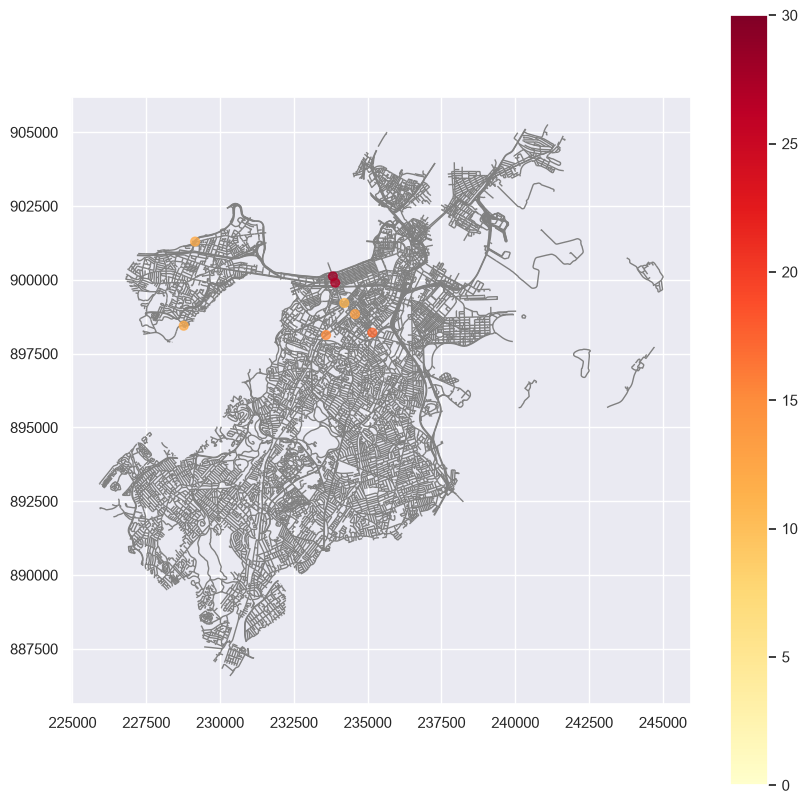

In [15]:
# plot map
f, ax = plt.subplots(figsize=(10, 10))
# tract_data.to_crs(house_data.crs).plot(ax=ax)
# house_data.plot(ax=ax)
boston_roads.plot(ax=ax,linewidth=1, color="gray", zorder=1)
intersections.plot(ax=ax, markersize=40, column="value",               # the column that sets the color
    cmap="YlOrRd", zorder=3, alpha=0.75, legend=True, vmin=0, vmax=30)
f.savefig("top_crash_intersections_map.png", dpi=500, bbox_inches="tight")

In [16]:
# bike blocking

# read in data
data_file = "/Users/diksh/Documents/BCU/AnnualReport2026/data/blocks/bike-bureau-reports-2026-10-28.csv"
dat = pd.read_csv(data_file)
dat = dat[(dat["timestamp"] >= "2026-01-01") & (dat['city'] == 'Boston, MA')]

# map to the nearest street from the given coordinates
streets=[]
for i in range(dat.shape[0]):
    street = gis.street_from_coords(dat.iloc[i].lat, dat.iloc[i].lon, boston_roads)
    streets.append(street)
dat['Street'] = streets

Text(0.5, 1.0, 'Blocked Bike Lanes in 2026')

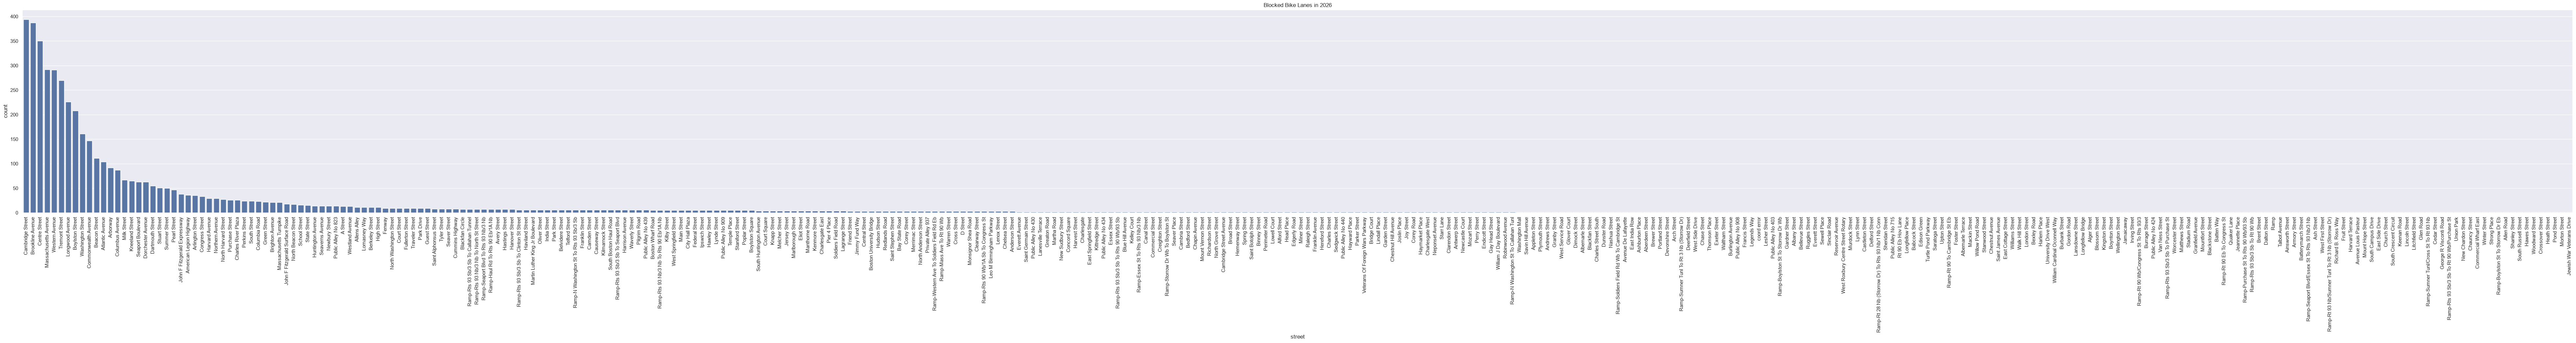

In [17]:
# count reports on each street
cts = Counter(dat['Street'])
# cts
ct_df = pd.DataFrame(cts.items(), columns=["street", "count"])
ct_df=ct_df.sort_values('count', ascending=False)
plt.xticks(rotation=90)
p = sns.barplot(data=ct_df, x = 'street', y = 'count')
p.set_title("Blocked Bike Lanes in 2026")


In [19]:
# count reports on each street
cts = Counter(dat['Street'])
# cts
ct_df = pd.DataFrame(cts.items(), columns=["street", "count"])

# get the length of each street
ct_df['length'] = 0.0
for i in ct_df.index:
    st = ct_df.loc[i, 'street']
    if st == 'coord error':
        continue
    else:
        # print(st)
        l = gis.street_length(city=boston_roads, target_street=st, units='miles')
        # print(l)
        ct_df.loc[i, 'length'] = l
ct_df['reportsPerMile'] = ct_df['count']/ct_df['length'] # normalize coutns by length

# order by coutns per mile
ct_df=ct_df.sort_values("reportsPerMile", ascending=False)
# write to file
ct_df.to_csv('C:/Users/diksh/Documents/BCU/AnnualReport2026/analysis/bike_block_reportCts.csv')
ct_df.head

<bound method NDFrame.head of                                street  count    length  reportsPerMile
197                       coord error      1  0.000000             inf
315                   Haymarket Place      2  0.004017      497.825940
71                Charles River Plaza     26  0.077160      336.962964
0                    Brookline Avenue    387  1.153119      335.611641
359               Public Alley No 823     14  0.043385      322.688736
..                                ...    ...       ...             ...
361         Jewish War Veterans Drive      1  2.832934        0.352991
253                    Perimeter Road      2  7.039515        0.284110
170                  Blue Hill Avenue      2  7.217699        0.277097
322  Veterans Of Foreign Wars Parkway      2  7.822768        0.255664
360                     Morton Street      1  4.733774        0.211248

[362 rows x 4 columns]>

In [20]:
# streets = ct_df['street'][1:11].tolist()
# streets
# get top streets
ct_df.iloc[0:11,:]

# technically some "streets" are very high because they are so short and have just a couple of reports. 
# should we remove streets that are too short?

,street,count,length,reportsPerMile
197,coord error,1,0.000000,inf
315,Haymarket Place,2,0.004017,497.825940
71,Charles River Plaza,26,0.077160,336.962964
0,Brookline Avenue,387,1.153119,335.611641
359,Public Alley No 823,14,0.043385,322.688736
9,Longwood Avenue,226,0.705551,320.316886
99,Allens Alley,11,0.041640,264.169202
4,Kneeland Street,65,0.323203,201.112012
192,Reservoir Avenue,1,0.005742,174.156815
20,Western Avenue,291,1.806598,161.076246


In [21]:
streets = ct_df['street'][1:30]
# split streets into segments and counts per segment
segs = gis.split_streets(boston_roads, streets, seg_length=1609)
segs = gis.count_points_along_segments(segs, dat, lat_col='lat', long_col='lon')
segs
segs_df = segs.drop(labels='geometry',axis=1)
segs_df.to_csv('C:/Users/diksh/Documents/BCU/AnnualReport2026/analysis/bike_block_street_segments.csv')

In [22]:
# filter streets with at least 3 counts and at least 0.01 miles
ct_df = ct_df[(ct_df['count'] >= 3) & ct_df['length'] >= 0.01]
all_tgt_streets = list(set(ct_df['street']))
# print(len(all_tgt_streets))

# get all 0.5 mi segments at each 0.1 interval
segment_length_miles = 0.5
frame_length_miles = 0.1 
segs = gis.split_streets(boston_roads, all_tgt_streets, 
                         seg_length=segment_length_miles*1609.344, frame_length=frame_length_miles*1609.344)
# count reports within each segment
segs = gis.count_points_along_segments(segs, dat, lat_col='lat', long_col='lon')
segs = segs[segs['count'] > 10]
segs = segs.sort_values('count', ascending=False)
# segs
segs_df = segs.drop(labels='geometry',axis=1)
# write to file
segs_df.to_csv('C:/Users/diksh/Documents/BCU/AnnualReport2026/analysis/bike_block_street_segmentsFrameShift.csv')

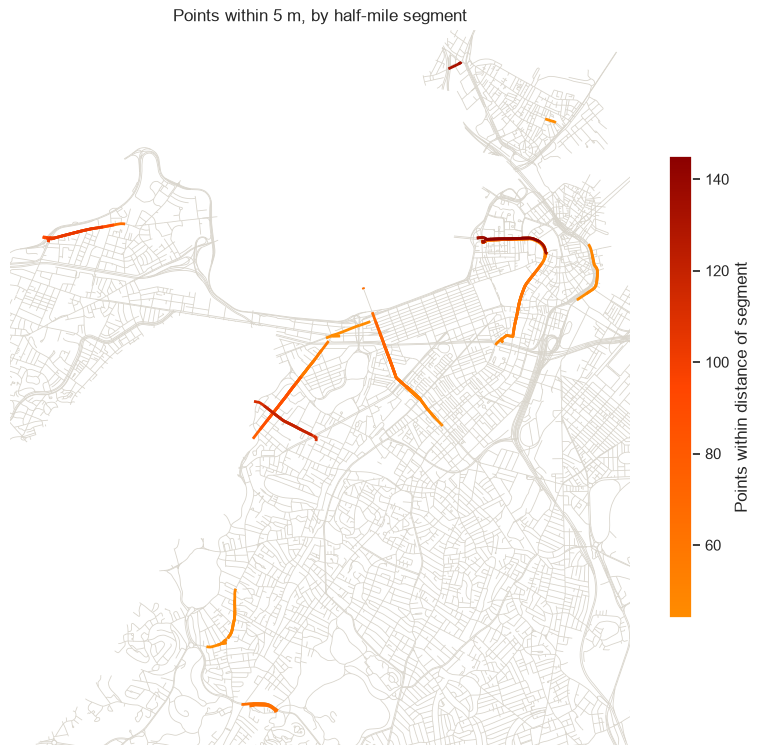

In [23]:
# plot top 50 segments
plot_segs = segs[1:50]
plot_segs = plot_segs.sort_values('count', ascending=True)
gis.plot_segment_counts(plot_segs, background=boston_roads, 
                        title="Points within 5 m, by half-mile segment", 
                        cmap=LinearSegmentedColormap.from_list("col", ["darkorange", "orangered", "darkred"]),
                       linewidth=2)
plt.show()